# 💬 Détection de Spam — Classification Binaire avec MLP PyTorch

**Objectif** : Classifier des SMS/e-mails en **Spam (1)** ou **Ham (0)** en encodant les features textuelles numériquement, puis entraîner un réseau MLP PyTorch avec régularisation.

| Élément | Détail |
|---|---|
| **Type** | Classification binaire |
| **Dataset** | SMS Spam Collection (5 572 messages) |
| **Encodage texte** | TF-IDF (Term Frequency–Inverse Document Frequency) |
| **Architecture** | MLP : TF-IDF → 256 → 128 → 64 → 1 |
| **Loss** | BCEWithLogitsLoss |
| **Optimizer** | Adam |
| **Régularisation** | Dropout + Early Stopping |
| **Métrique** | Accuracy, Precision, Recall, F1 |

## 1. Import des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn — prétraitement et évaluation
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc)

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import warnings
warnings.filterwarnings('ignore')

# Reproductibilité
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device : {device}")
print(f"PyTorch : {torch.__version__}")
print("Bibliothèques importées ✔")

Device : cuda
PyTorch : 2.4.1+cu124
Bibliothèques importées ✔


## 2. Chargement & exploration du dataset SMS Spam Collection

In [2]:
import urllib.request, os, zipfile

# Téléchargement automatique du dataset SMS Spam Collection (UCI)
DATA_URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
ZIP_PATH  = "smsspamcollection.zip"
DATA_FILE = "SMSSpamCollection"

if not os.path.exists(DATA_FILE):
    print("Téléchargement du dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(".")
    print("Dataset téléchargé ✔")
else:
    print("Dataset déjà présent ✔")

# Chargement
df = pd.read_csv(DATA_FILE, sep='\t', header=None, names=['label', 'text'])

print(f"\nShape : {df.shape}")
print(f"\nDistribution des classes :")
print(df['label'].value_counts())
print(f"\nExemples de messages :")
df.head(10)

Téléchargement du dataset...
Dataset téléchargé ✔

Shape : (5572, 2)

Distribution des classes :
label
ham     4825
spam     747
Name: count, dtype: int64

Exemples de messages :


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


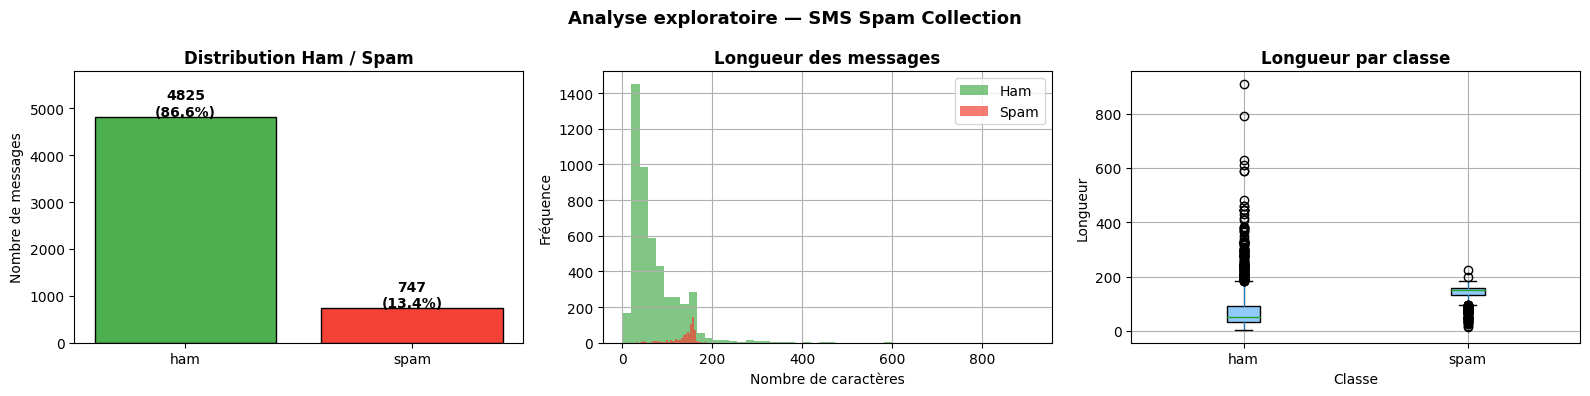


Valeurs manquantes : {'label': 0, 'text': 0}
Longueur moyenne Ham  : 71 caractères
Longueur moyenne Spam : 139 caractères


In [3]:
# ─── Exploration visuelle ─────────────────────────────────────────────────────
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})
df['text_len']  = df['text'].str.len()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Distribution des classes
counts = df['label'].value_counts()
colors = ['#4CAF50', '#F44336']
bars = axes[0].bar(counts.index, counts.values, color=colors, edgecolor='black')
axes[0].set_title('Distribution Ham / Spam', fontweight='bold')
axes[0].set_ylabel('Nombre de messages')
for bar, cnt in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                 f'{cnt}\n({cnt/len(df)*100:.1f}%)', ha='center', fontweight='bold')
axes[0].set_ylim(0, max(counts.values) * 1.2)

# 2. Longueur des messages par classe
df[df['label']=='ham']['text_len'].hist(ax=axes[1], bins=50, color='#4CAF50', alpha=0.7, label='Ham')
df[df['label']=='spam']['text_len'].hist(ax=axes[1], bins=50, color='#F44336', alpha=0.7, label='Spam')
axes[1].set_title('Longueur des messages', fontweight='bold')
axes[1].set_xlabel('Nombre de caractères')
axes[1].set_ylabel('Fréquence')
axes[1].legend()

# 3. Boxplot longueur
df.boxplot(column='text_len', by='label', ax=axes[2],
           patch_artist=True,
           boxprops=dict(facecolor='#90CAF9'))
axes[2].set_title('Longueur par classe', fontweight='bold')
axes[2].set_xlabel('Classe')
axes[2].set_ylabel('Longueur')
plt.suptitle('')

plt.suptitle('Analyse exploratoire — SMS Spam Collection', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nValeurs manquantes : {df[['label','text']].isnull().sum().to_dict()}")
print(f"Longueur moyenne Ham  : {df[df['label']=='ham']['text_len'].mean():.0f} caractères")
print(f"Longueur moyenne Spam : {df[df['label']=='spam']['text_len'].mean():.0f} caractères")

## 3. Prétraitement — TF-IDF + StandardScaler + Split

> **TF-IDF** (Term Frequency–Inverse Document Frequency) convertit chaque message texte en un vecteur numérique en pondérant l'importance de chaque mot.
> - **TF** : fréquence du mot dans le message
> - **IDF** : inverse de la fréquence dans tous les messages (rare = plus informatif)

In [4]:
# ─── 1. Gestion des valeurs manquantes ───────────────────────────────────────
df['text'] = df['text'].fillna('')          # si texte NaN → chaîne vide

# ─── 2. Labels : ham=0, spam=1 ───────────────────────────────────────────────
y = df['label_num'].values.astype(np.float32)

# ─── 3. TF-IDF : texte → vecteur numérique ───────────────────────────────────
MAX_FEATURES = 3000   # vocabulaire limité aux 3000 mots les plus fréquents

tfidf = TfidfVectorizer(
    max_features  = MAX_FEATURES,
    ngram_range   = (1, 2),      # unigrammes + bigrammes
    stop_words    = 'english',   # supprimer les mots vides
    sublinear_tf  = True         # TF logarithmique (réduit l'effet des mots très fréquents)
)
X = tfidf.fit_transform(df['text']).toarray().astype(np.float32)

print(f"Shape TF-IDF : {X.shape}  ({X.shape[0]} messages × {X.shape[1]} features)")

# ─── 4. StandardScaler ───────────────────────────────────────────────────────
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype(np.float32)

# ─── 5. Split : 70% train | 15% val | 15% test ── stratifié ─────────────────
X_train, X_temp, y_train, y_temp = train_test_split(
    X_scaled, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print(f"\nSplit :")
print(f"  Train : {len(X_train):4d}  (spam={int(y_train.sum()):3d}  ham={int((y_train==0).sum()):4d})")
print(f"  Val   : {len(X_val):4d}  (spam={int(y_val.sum()):3d}  ham={int((y_val==0).sum()):4d})")
print(f"  Test  : {len(X_test):4d}  (spam={int(y_test.sum()):3d}  ham={int((y_test==0).sum()):4d})")
print(f"\nInput dim : {X_train.shape[1]}")

Shape TF-IDF : (5572, 3000)  (5572 messages × 3000 features)

Split :
  Train : 3900  (spam=523  ham=3377)
  Val   :  836  (spam=112  ham= 724)
  Test  :  836  (spam=112  ham= 724)

Input dim : 3000


## 4. Dataset PyTorch & DataLoaders

In [5]:
class SpamDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)  # (N,1) pour BCELoss

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 32

train_loader = DataLoader(SpamDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(SpamDataset(X_val,   y_val),   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(SpamDataset(X_test,  y_test),  batch_size=BATCH_SIZE, shuffle=False)

print(f"Batch size    : {BATCH_SIZE}")
print(f"Train batches : {len(train_loader)}")
print(f"Val   batches : {len(val_loader)}")
print(f"Test  batches : {len(test_loader)}")
print("DataLoaders prêts ✔")

Batch size    : 32
Train batches : 122
Val   batches : 27
Test  batches : 27
DataLoaders prêts ✔


## 5. Architecture du MLP

```
TF-IDF (3000)
   ↓
Dense(256) → BatchNorm → ReLU → Dropout(0.4)
   ↓
Dense(128) → BatchNorm → ReLU → Dropout(0.3)
   ↓
Dense(64)  → BatchNorm → ReLU → Dropout(0.2)
   ↓
Dense(1)   → Sigmoid (via BCEWithLogitsLoss)
```

In [6]:
class SpamClassifier(nn.Module):
    """MLP binaire pour la détection de spam."""

    def __init__(self, input_dim):
        super(SpamClassifier, self).__init__()
        self.network = nn.Sequential(
            # Couche 1 : input → 256
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.4),

            # Couche 2 : 256 → 128
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Couche 3 : 128 → 64
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Sortie binaire : 64 → 1  (pas de Sigmoid → intégré dans BCEWithLogitsLoss)
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


INPUT_DIM = X_train.shape[1]
model = SpamClassifier(input_dim=INPUT_DIM).to(device)

print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nParamètres entraînables : {total_params:,}")

SpamClassifier(
  (network): Sequential(
    (0): Linear(in_features=3000, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)

Paramètres entraînables : 810,369


## 6. Entraînement avec Early Stopping

In [7]:
# ─── Hyperparamètres ──────────────────────────────────────────────────────────
EPOCHS   = 100
LR       = 1e-3
PATIENCE = 15

# Poids pour rééquilibrer (le dataset est déséquilibré : ~87% ham / 13% spam)
pos_weight = torch.tensor([(y_train == 0).sum() / y_train.sum()], dtype=torch.float32).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=8, factor=0.5, verbose=True)

# ─── Boucle d'entraînement ────────────────────────────────────────────────────
def run_epoch(model, loader, criterion, optimizer, device, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for X_b, y_b in loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            if train:
                optimizer.zero_grad()
            logits = model(X_b)
            loss   = criterion(logits, y_b)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y_b)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            correct += (preds == y_b).sum().item()
            total   += len(y_b)
    return total_loss / total, correct / total


history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss    = float('inf')
patience_counter = 0

print(f"{'Epoch':>6} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}")
print("-" * 56)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, device, train=True)
    vl_loss, vl_acc = run_epoch(model, val_loader,   criterion, optimizer, device, train=False)
    scheduler.step(vl_loss)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)

    if epoch % 10 == 0 or epoch == 1:
        print(f"{epoch:>6} | {tr_loss:>10.4f} | {tr_acc*100:>8.2f}% | {vl_loss:>8.4f} | {vl_acc*100:>6.2f}%")

    if vl_loss < best_val_loss:
        best_val_loss    = vl_loss
        patience_counter = 0
        torch.save(model.state_dict(), 'mlp_spam_best.pth')
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n⏹ Early stopping à l'epoch {epoch}")
            break

print(f"\n✅ Terminé — Meilleur val_loss : {best_val_loss:.4f}")

 Epoch | Train Loss | Train Acc | Val Loss | Val Acc
--------------------------------------------------------
     1 |     0.6114 |    82.77% |   0.2720 |  97.25%
    10 |     0.0552 |    99.10% |   0.3474 |  97.97%

⏹ Early stopping à l'epoch 17

✅ Terminé — Meilleur val_loss : 0.2398


## 7. Courbes d'apprentissage

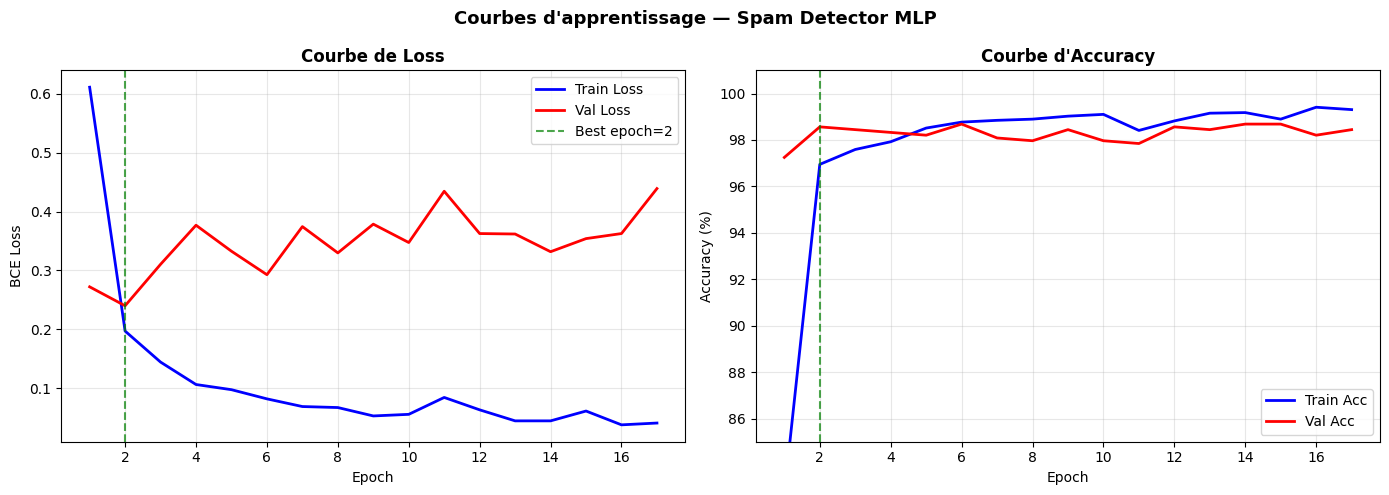

Meilleur epoch   : 2
Meilleur val_acc : 98.68%


In [8]:
epochs_ran = range(1, len(history['train_loss']) + 1)
best_ep    = np.argmin(history['val_loss']) + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss
ax1.plot(epochs_ran, history['train_loss'], 'b-', label='Train Loss', linewidth=2)
ax1.plot(epochs_ran, history['val_loss'],   'r-', label='Val Loss',   linewidth=2)
ax1.axvline(best_ep, color='green', linestyle='--', alpha=0.7, label=f'Best epoch={best_ep}')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('BCE Loss')
ax1.set_title('Courbe de Loss', fontweight='bold')
ax1.legend(); ax1.grid(True, alpha=0.3)

# Accuracy
ax2.plot(epochs_ran, [a*100 for a in history['train_acc']], 'b-', label='Train Acc', linewidth=2)
ax2.plot(epochs_ran, [a*100 for a in history['val_acc']],   'r-', label='Val Acc',   linewidth=2)
ax2.axvline(best_ep, color='green', linestyle='--', alpha=0.7)
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)')
ax2.set_title("Courbe d'Accuracy", fontweight='bold')
ax2.set_ylim(85, 101)
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.suptitle("Courbes d'apprentissage — Spam Detector MLP", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('spam_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Meilleur epoch   : {best_ep}")
print(f"Meilleur val_acc : {max(history['val_acc'])*100:.2f}%")

## 8. Évaluation sur le jeu de test — Accuracy · Matrice de confusion · Courbe ROC

In [9]:
# Charger le meilleur modèle
model.load_state_dict(torch.load('mlp_spam_best.pth', map_location=device))
model.eval()

# Prédictions
all_logits, all_preds, all_labels = [], [], []
with torch.no_grad():
    for X_b, y_b in test_loader:
        X_b = X_b.to(device)
        logits = model(X_b)
        probs  = torch.sigmoid(logits).cpu().squeeze().tolist()
        preds  = (torch.sigmoid(logits) >= 0.5).float().cpu().squeeze().tolist()
        all_logits.extend(probs if isinstance(probs, list) else [probs])
        all_preds.extend(preds if isinstance(preds, list)  else [preds])
        all_labels.extend(y_b.squeeze().tolist())

y_pred  = np.array(all_preds,  dtype=int)
y_proba = np.array(all_logits, dtype=float)
y_true  = np.array(all_labels, dtype=int)

test_acc = accuracy_score(y_true, y_pred)
print(f"{'='*50}")
print(f"  TEST ACCURACY : {test_acc*100:.2f}%")
print(f"{'='*50}")
print()
print("=== Rapport de classification ===")
print(classification_report(y_true, y_pred, target_names=['Ham (0)', 'Spam (1)'], digits=4))

  TEST ACCURACY : 98.44%

=== Rapport de classification ===
              precision    recall  f1-score   support

     Ham (0)     0.9877    0.9945    0.9911       724
    Spam (1)     0.9626    0.9196    0.9406       112

    accuracy                         0.9844       836
   macro avg     0.9751    0.9571    0.9658       836
weighted avg     0.9843    0.9844    0.9843       836



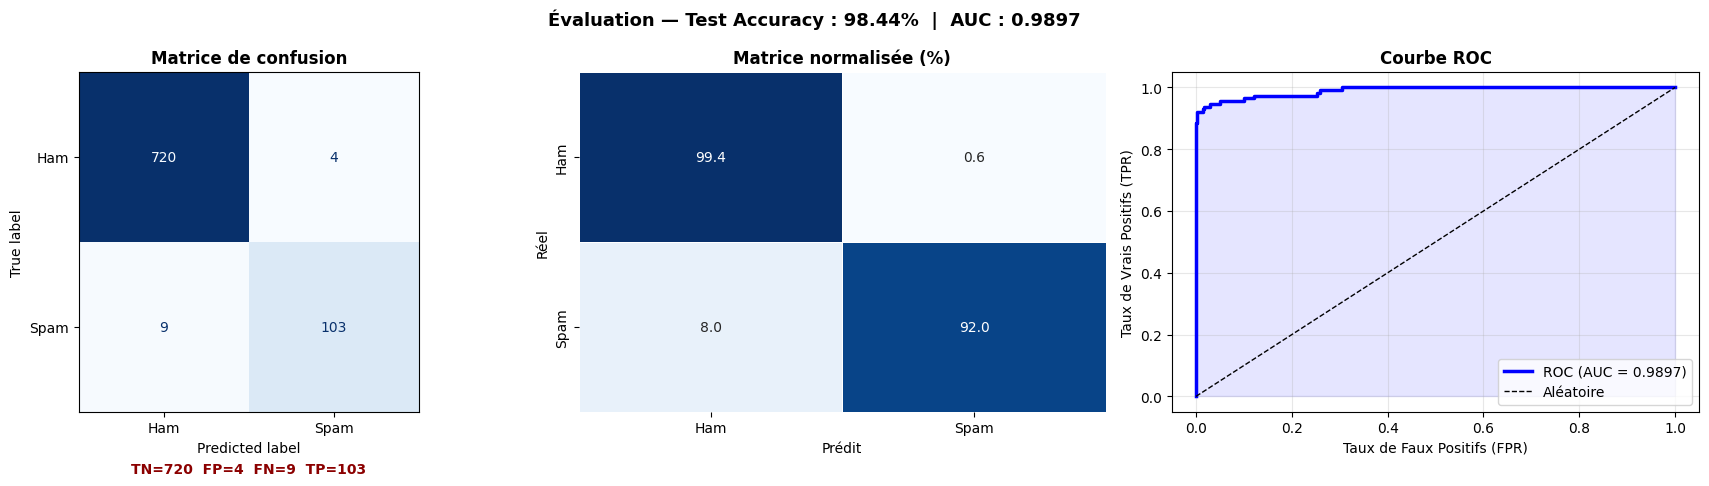

AUC-ROC : 0.9897
Précision Spam (éviter les faux positifs) : 96.26%
Rappel    Spam (détecter tous les spams)  : 91.96%


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ─── Matrice de confusion ─────────────────────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ham', 'Spam'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Matrice de confusion', fontweight='bold')

# Annotations TP/TN/FP/FN
axes[0].text(0.5, -0.18, f'TN={tn}  FP={fp}  FN={fn}  TP={tp}',
             transform=axes[0].transAxes, ha='center', fontsize=10,
             color='darkred', fontweight='bold')

# ─── Matrice normalisée ───────────────────────────────────────────────────────
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'],
            ax=axes[1], linewidths=0.5, cbar=False)
axes[1].set_xlabel('Prédit'); axes[1].set_ylabel('Réel')
axes[1].set_title('Matrice normalisée (%)', fontweight='bold')

# ─── Courbe ROC ───────────────────────────────────────────────────────────────
fpr, tpr, _ = roc_curve(y_true, y_proba)
roc_auc     = auc(fpr, tpr)

axes[2].plot(fpr, tpr, 'b-', linewidth=2.5, label=f'ROC (AUC = {roc_auc:.4f})')
axes[2].plot([0,1], [0,1], 'k--', linewidth=1, label='Aléatoire')
axes[2].fill_between(fpr, tpr, alpha=0.1, color='blue')
axes[2].set_xlabel('Taux de Faux Positifs (FPR)')
axes[2].set_ylabel('Taux de Vrais Positifs (TPR)')
axes[2].set_title('Courbe ROC', fontweight='bold')
axes[2].legend(loc='lower right')
axes[2].grid(True, alpha=0.3)

plt.suptitle(f'Évaluation — Test Accuracy : {test_acc*100:.2f}%  |  AUC : {roc_auc:.4f}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('spam_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"AUC-ROC : {roc_auc:.4f}")
print(f"Précision Spam (éviter les faux positifs) : {tp/(tp+fp)*100:.2f}%")
print(f"Rappel    Spam (détecter tous les spams)  : {tp/(tp+fn)*100:.2f}%")

## 9. Sauvegarde du modèle & Inférence sur de nouveaux messages

In [11]:
import pickle

# ─── Sauvegarde ───────────────────────────────────────────────────────────────
torch.save(model.state_dict(), 'mlp_spam_classifier.pth')
with open('spam_tfidf.pkl', 'wb') as f:
    pickle.dump(tfidf, f)
with open('spam_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("Modèle sauvegardé  : mlp_spam_classifier.pth")
print("TF-IDF sauvegardé  : spam_tfidf.pkl")
print("Scaler sauvegardé  : spam_scaler.pkl")


# ─── Fonction de prédiction ───────────────────────────────────────────────────
def predict_spam(messages: list[str], threshold: float = 0.5) -> None:
    """Prédit si chaque message est spam ou ham."""
    model.eval()
    x = tfidf.transform(messages).toarray().astype(np.float32)
    x = scaler.transform(x).astype(np.float32)
    x_t = torch.tensor(x, dtype=torch.float32).to(device)
    with torch.no_grad():
        proba = torch.sigmoid(model(x_t)).cpu().squeeze().numpy()
    if proba.ndim == 0:
        proba = proba.reshape(1)
    print(f"\n{'─'*65}")
    print(f"{'Message':<45} {'Proba':>7}  {'Résultat'}")
    print(f"{'─'*65}")
    for msg, p in zip(messages, proba):
        label = '🚨 SPAM' if p >= threshold else '✅  Ham'
        print(f"{msg[:44]:<45} {p*100:>6.2f}%  {label}")
    print(f"{'─'*65}")


# ─── Test sur des exemples ────────────────────────────────────────────────────
new_messages = [
    "Congratulations! You've won a FREE iPhone. Click here now to claim your prize!",
    "Hey, are we still on for lunch tomorrow at noon?",
    "URGENT: Your bank account has been compromised. Call us immediately at 0800-FREE.",
    "Don't forget to bring the report to the meeting on Monday.",
    "You have been selected for a £1000 cash reward. Text WIN to 80888 now.",
    "Can you send me the slides from this morning's presentation? Thanks!",
]

predict_spam(new_messages)

Modèle sauvegardé  : mlp_spam_classifier.pth
TF-IDF sauvegardé  : spam_tfidf.pkl
Scaler sauvegardé  : spam_scaler.pkl

─────────────────────────────────────────────────────────────────
Message                                         Proba  Résultat
─────────────────────────────────────────────────────────────────
Congratulations! You've won a FREE iPhone. C   97.16%  🚨 SPAM
Hey, are we still on for lunch tomorrow at n    1.96%  ✅  Ham
URGENT: Your bank account has been compromis   86.57%  🚨 SPAM
Don't forget to bring the report to the meet    3.11%  ✅  Ham
You have been selected for a £1000 cash rewa   99.38%  🚨 SPAM
Can you send me the slides from this morning    2.38%  ✅  Ham
─────────────────────────────────────────────────────────────────
